In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load dataset
df = pd.read_csv("academic Stress level - maintainance 1.csv")


In [15]:
# First 5 rows
print(df.head())

# Dataset summary
print(df.info())

# Shape (rows, columns)
print("Shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())

# Missing values
print("Missing values per column:\n", df.isnull().sum())


             Timestamp Your Academic Stage  Peer pressure  \
0  24/07/2025 22:05:39       undergraduate              4   
1  24/07/2025 22:05:52       undergraduate              3   
2  24/07/2025 22:06:39       undergraduate              1   
3  24/07/2025 22:06:45       undergraduate              3   
4  24/07/2025 22:08:06       undergraduate              3   

   Academic pressure from your home Study Environment  \
0                                 5             Noisy   
1                                 4          Peaceful   
2                                 1          Peaceful   
3                                 2          Peaceful   
4                                 3          Peaceful   

          What coping strategy you use as a student?  \
0  Analyze the situation and handle it with intel...   
1  Analyze the situation and handle it with intel...   
2                   Social support (friends, family)   
3  Analyze the situation and handle it with intel...   
4  Analyze

In [16]:
# For numerical columns
print(df.describe())

# For categorical columns
print(df.describe(include=['object']))


       Peer pressure  Academic pressure from your home  \
count     140.000000                        140.000000   
mean        3.071429                          3.178571   
std         1.083844                          1.276618   
min         1.000000                          1.000000   
25%         2.000000                          2.000000   
50%         3.000000                          3.000000   
75%         4.000000                          4.000000   
max         5.000000                          5.000000   

       What would you rate the academic  competition in your student life  \
count                                         140.000000                    
mean                                            3.492857                    
std                                             1.028349                    
min                                             1.000000                    
25%                                             3.000000                    
50%            

In [13]:
import pandas as pd
import numpy  as np
df= pd.read_csv("academic Stress level - maintainance 1.csv ") 


# Clean column names: remove spaces, % signs, lowercase everything
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")
df.columns = df.columns.str.replace("%", "percent")
df.columns = df.columns.str.lower()
print(df.columns.tolist())


['timestamp', 'your_academic_stage', 'peer_pressure', 'academic_pressure_from_your_home', 'study_environment', 'what_coping_strategy_you_use_as_a_student?', 'do_you_have_any_bad_habits_like_smoking,_drinking_on_a_daily_basis?', 'what_would_you_rate_the_academic__competition_in_your_student_life', 'rate_your_academic_stress_index']


In [33]:
# TO CLEAN THE FILES
# 1. Check missing values
print("Missing values per column:\n", df.isnull().sum())

# 2. Handle duplicates
print("\nNumber of duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# 3. Clean numeric column (stress_index)
# Remove spaces, convert to numeric (if stored as string)
df["stress_index"] = pd.to_numeric(df["stress_index"], errors="coerce")

# 4. Fill or drop missing values
# Example: fill numeric with mean
df["stress_index"] = df["stress_index"].fillna(df["stress_index"].mean())

# Example: fill categorical with mode
categorical_cols = ["academic_stage", "peer_pressure", "home_pressure", 
                    "study_environment", "coping_strategy", "bad_habits", "competition_rating"]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 5. Verify cleaning
print("\nMissing values after cleaning:\n", df.isnull().sum())
print("\nDataset shape after cleaning:", df.shape)


# Drop empty rows (if any)
df = df.dropna()

# OR fill missing numeric values with mean
# df['column_name'] = df['column_name'].fillna(df['column_name'].mean())


Missing values per column:
 timestamp             0
academic_stage        0
peer_pressure         0
home_pressure         0
study_environment     0
coping_strategy       0
bad_habits            0
competition_rating    0
stress_index          0
dtype: int64

Number of duplicate rows: 0

Missing values after cleaning:
 timestamp             0
academic_stage        0
peer_pressure         0
home_pressure         0
study_environment     0
coping_strategy       0
bad_habits            0
competition_rating    0
stress_index          0
dtype: int64

Dataset shape after cleaning: (139, 9)


In [20]:
print(df.columns.tolist())


['Timestamp', 'Your Academic Stage', 'Peer pressure', 'Academic pressure from your home', 'Study Environment', 'What coping strategy you use as a student?', 'Do you have any bad habits like smoking, drinking on a daily basis?', 'What would you rate the academic  competition in your student life', 'Rate your academic stress index ']


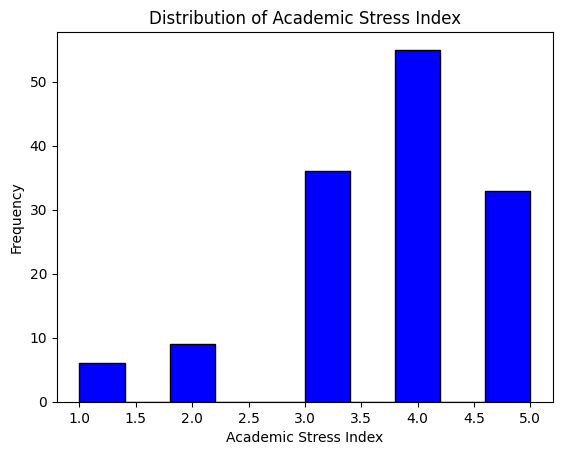

In [ ]:
#HISTOGRAM OF STRESS INDEX
plt.hist(df["Rate your academic stress index "], bins=10, color="blue", edgecolor="black")
plt.xlabel("Academic Stress Index")
plt.ylabel("Frequency")
plt.title("Distribution of Academic Stress Index")
plt.show()


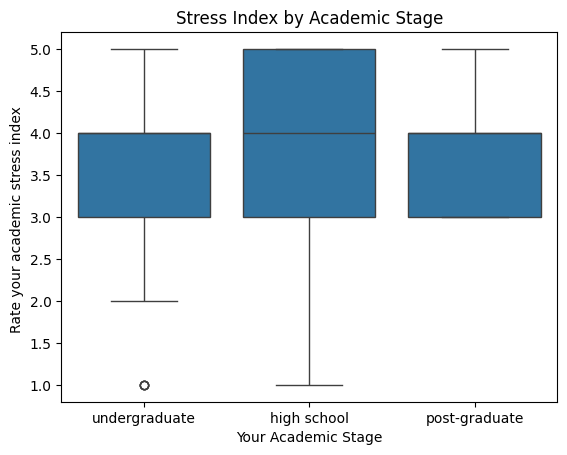

In [25]:
#BOXPLOT:STRESS VS ACADEMIC STAGE

sns.boxplot(x="Your Academic Stage", 
            y="Rate your academic stress index ", 
            data=df)
plt.title("Stress Index by Academic Stage")
plt.show()




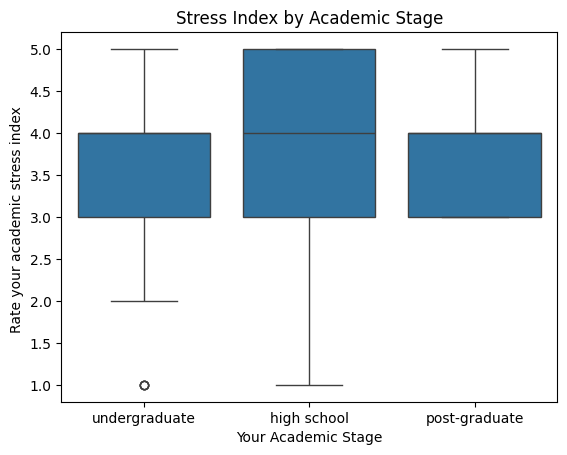

In [27]:
#BOXPLOT:STRESS VS PEER PRESSURE
sns.boxplot(x="Your Academic Stage", 
            y="Rate your academic stress index ", 
            data=df)
plt.title("Stress Index by Academic Stage")
plt.show()



In [28]:
#SORRY I HAD TO RENAME CAUSE THE NAMES ARE GIVING ME TROUBLES,I KEEP GETTING DIFFERENT ERRORS
df = df.rename(columns={
    "Timestamp": "timestamp",
    "Your Academic Stage": "academic_stage",
    "Peer pressure": "peer_pressure",
    "Academic pressure from your home": "home_pressure",
    "Study Environment": "study_environment",
    "What coping strategy you use as a student?": "coping_strategy",
    "Do you have any bad habits like smoking, drinking on a daily basis?": "bad_habits",
    "What would you rate the academic  competition in your student life": "competition_rating",
    "Rate your academic stress index ": "stress_index"
})

print(df.columns.tolist())


['timestamp', 'academic_stage', 'peer_pressure', 'home_pressure', 'study_environment', 'coping_strategy', 'bad_habits', 'competition_rating', 'stress_index']


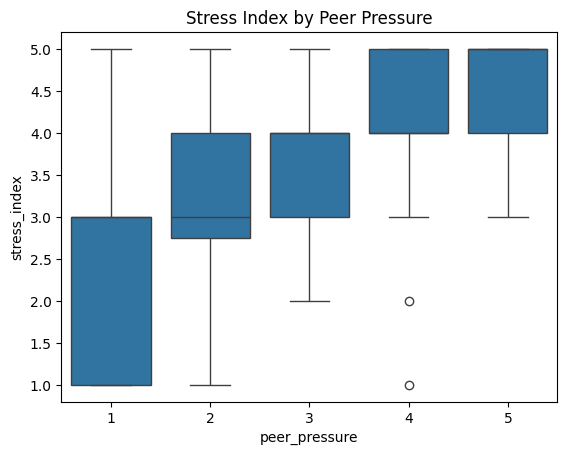

In [30]:
#BOXPLOT:STRESS VS PEER PRESSURE
sns.boxplot(x="peer_pressure", 
            y="stress_index", 
            data=df)
plt.title("Stress Index by Peer Pressure")
plt.show()


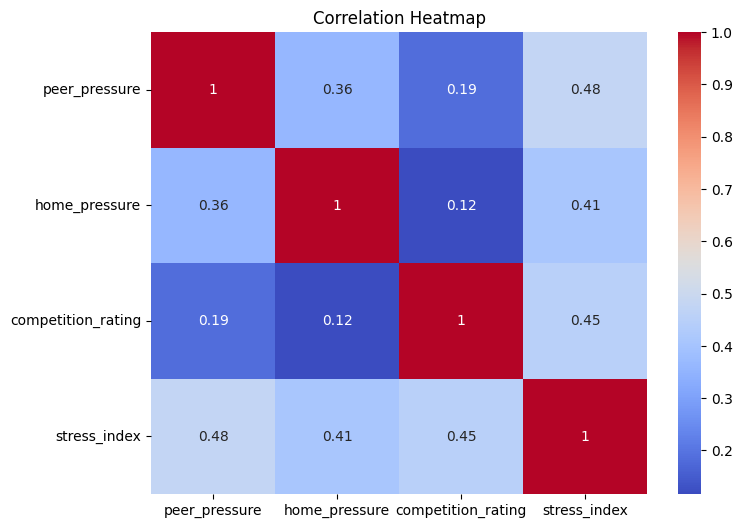

In [31]:
#CORRELATION HEATMAP
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [32]:
#ANOVA
# ANOVA: Stress Index across Academic Stages
groups = [group["stress_index"].values 
          for name, group in df.groupby("academic_stage")]

from scipy import stats
f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Significant difference in Stress Levels across Academic Stages.")
else:
    print("No significant difference.")


F-statistic: 0.2049385645095568
p-value: 0.8149484971446279
No significant difference.


In [ ]:
academic Stress level - maintainance 1.csv